# 01 — Data Preprocessing, EDA and Baseline Models
**Member 1.** Data quality checks, exploratory analysis, the common experimental
protocol, and two reference models: a majority-class baseline and Linear
Discriminant Analysis (LDA).

The protocol itself is implemented in `src/common.py` and imported by every notebook:

| Item | Choice |
|---|---|
| Positive class | malignant = 1 (benign = 0) |
| Train / test split | stratified 80 / 20, `random_state=42` (455 / 114 samples) |
| Model development | 5-fold stratified CV on the training set only, `random_state=42` |
| Metrics | accuracy, precision, malignant recall (sensitivity), specificity, F1, ROC-AUC, confusion matrix |
| Tuning criterion | malignant-class F1 (balances missed cancers against false alarms) |
| Test set | used once, in notebook 07, after all tuning |
| Leakage control | scaling / PCA / feature selection live inside sklearn `Pipeline`s |

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, shapiro, probplot
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform
from sklearn.linear_model import LinearRegression
from common import *
from models import build_pipeline, display_name

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160, "display.max_columns", 40)

## 1. Data quality

In [2]:
raw = load_raw()
print("shape:", raw.shape)
raw.head()

shape: (569, 32)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave_points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
print("missing values per column (total):", int(raw.isna().sum().sum()))
print("duplicate rows:", int(raw.duplicated().sum()))
print("duplicate rows ignoring id:", int(raw.drop(columns="id").duplicated().sum()))
print("duplicate ids:", int(raw["id"].duplicated().sum()))
print("diagnosis values:", raw["diagnosis"].unique())
print("negative feature values:", int((raw[FEATURE_NAMES] < 0).sum().sum()))
print("dtypes:", raw[FEATURE_NAMES].dtypes.unique())

missing values per column (total): 0
duplicate rows: 0
duplicate rows ignoring id: 0
duplicate ids: 0
diagnosis values: ['M' 'B']
negative feature values: 0
dtypes: [dtype('float64')]


The data are clean: no missing values, no duplicate records, only `M`/`B` labels and
no negative measurements. A handful of features contain exact zeros
(`concavity_*`, `concave_points_*`) — these are legitimate (nuclei with no concave
segments), not missing values, so they are kept.

In [4]:
zeros = (raw[FEATURE_NAMES] == 0).sum()
zeros[zeros > 0]

concavity_mean          13
concave_points_mean     13
concavity_se            13
concave_points_se       13
concavity_worst         13
concave_points_worst    13
dtype: int64

The `id` column is an identifier with no predictive meaning and is dropped
(`load_data()` returns only the 30 numeric features).

In [5]:
X, y = load_data()
X_train, X_test, y_train, y_test = get_split()
print("X:", X.shape, " train:", X_train.shape, " test:", X_test.shape)

X: (569, 30)  train: (455, 30)  test: (114, 30)


## 2. Class balance

In [6]:
bal = pd.DataFrame({
    "full": y.value_counts(),
    "train": y_train.value_counts(),
    "test": y_test.value_counts(),
}).rename(index={0: "benign", 1: "malignant"})
bal.loc["% malignant"] = (bal.loc["malignant"] / bal.sum() * 100).round(1)
bal

,full,train,test
malignant,,,
benign,357.0,285.0,72.0
malignant,212.0,170.0,42.0
% malignant,37.3,37.4,36.8


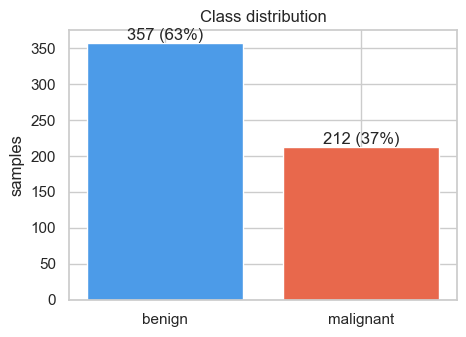

In [7]:
fig, ax = plt.subplots(figsize=(5, 3.5))
counts = y.map({0: "benign", 1: "malignant"}).value_counts()
ax.bar(counts.index, counts.values, color=["#4C9BE8", "#E8684C"])
for i, v in enumerate(counts.values):
    ax.text(i, v + 5, f"{v} ({v / len(y):.0%})", ha="center")
ax.set_ylabel("samples"); ax.set_title("Class distribution")
savefig(fig, "01_class_distribution"); plt.show()

The classes are moderately imbalanced (≈63 % benign, 37 % malignant). That is why
accuracy alone is not enough and why a majority-class model already scores ≈63 %.
The stratified split keeps the same ratio in train and test.

**From here on, all exploratory analysis uses the training set only**, so nothing we
learn about the data comes from the test set.

## 3. Feature distributions

In [8]:
train = X_train.assign(diagnosis=y_train.map({0: "benign", 1: "malignant"}))
X_train.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
radius_mean,455.0,14.166,3.579,6.981,11.710,13.340,15.935,28.110
texture_mean,455.0,19.418,4.291,9.710,16.335,18.900,21.830,39.280
perimeter_mean,455.0,92.216,24.717,43.790,75.235,86.180,104.500,188.500
area_mean,455.0,659.578,360.419,143.500,420.400,546.400,795.500,2501.000
smoothness_mean,455.0,0.096,0.014,0.063,0.085,0.095,0.105,0.163
compactness_mean,455.0,0.104,0.054,0.019,0.064,0.092,0.130,0.345
concavity_mean,455.0,0.089,0.082,0.000,0.030,0.059,0.132,0.427
concave_points_mean,455.0,0.049,0.040,0.000,0.020,0.033,0.074,0.201
symmetry_mean,455.0,0.181,0.028,0.106,0.162,0.180,0.195,0.304
fractal_dimension_mean,455.0,0.063,0.007,0.050,0.058,0.061,0.066,0.097


Feature scales differ by several orders of magnitude (e.g. `area_worst` up to
~4000 vs `fractal_dimension_se` ≈ 0.003), so standardisation is required for
distance- and margin-based models (KNN, SVM), regularised models (logistic
regression), and PCA.

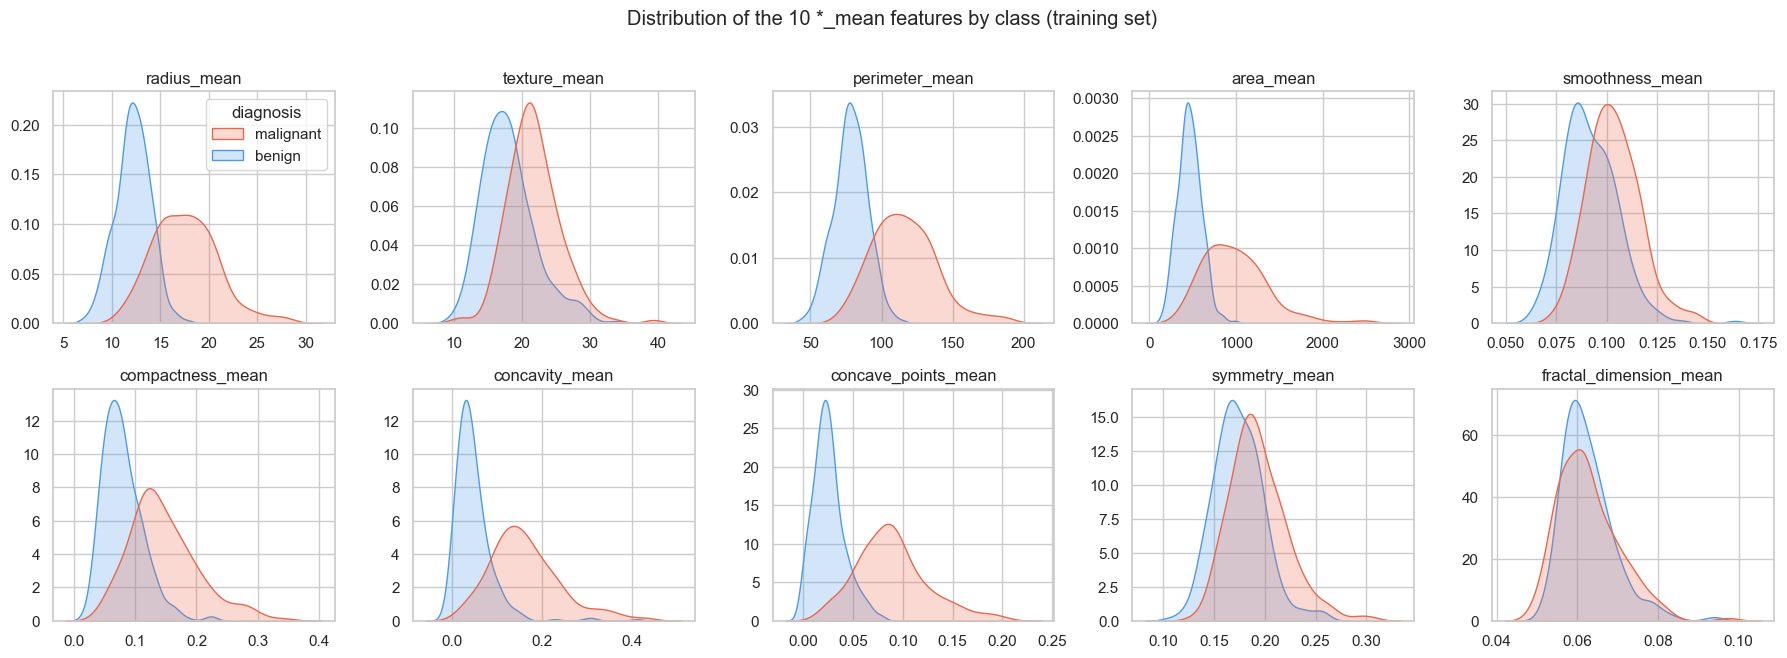

In [9]:
mean_feats = [f for f in FEATURE_NAMES if f.endswith("_mean")]
fig, axes = plt.subplots(2, 5, figsize=(18, 6.5))
for ax, f in zip(axes.flat, mean_feats):
    sns.kdeplot(data=train, x=f, hue="diagnosis", fill=True, common_norm=False,
                palette={"benign": "#4C9BE8", "malignant": "#E8684C"}, ax=ax, legend=ax is axes.flat[0])
    ax.set_title(f); ax.set_xlabel(""); ax.set_ylabel("")
fig.suptitle("Distribution of the 10 *_mean features by class (training set)", y=1.01)
fig.tight_layout(); savefig(fig, "01_mean_feature_kde"); plt.show()

In [10]:
sk = X_train.apply(skew).sort_values(ascending=False)
print("Most right-skewed features:\n", sk.head(8).round(2))

Most right-skewed features:
 area_se                 5.48
concavity_se            5.37
fractal_dimension_se    4.07
perimeter_se            3.51
radius_se               3.17
smoothness_se           2.45
symmetry_se             2.24
area_worst              1.90
dtype: float64


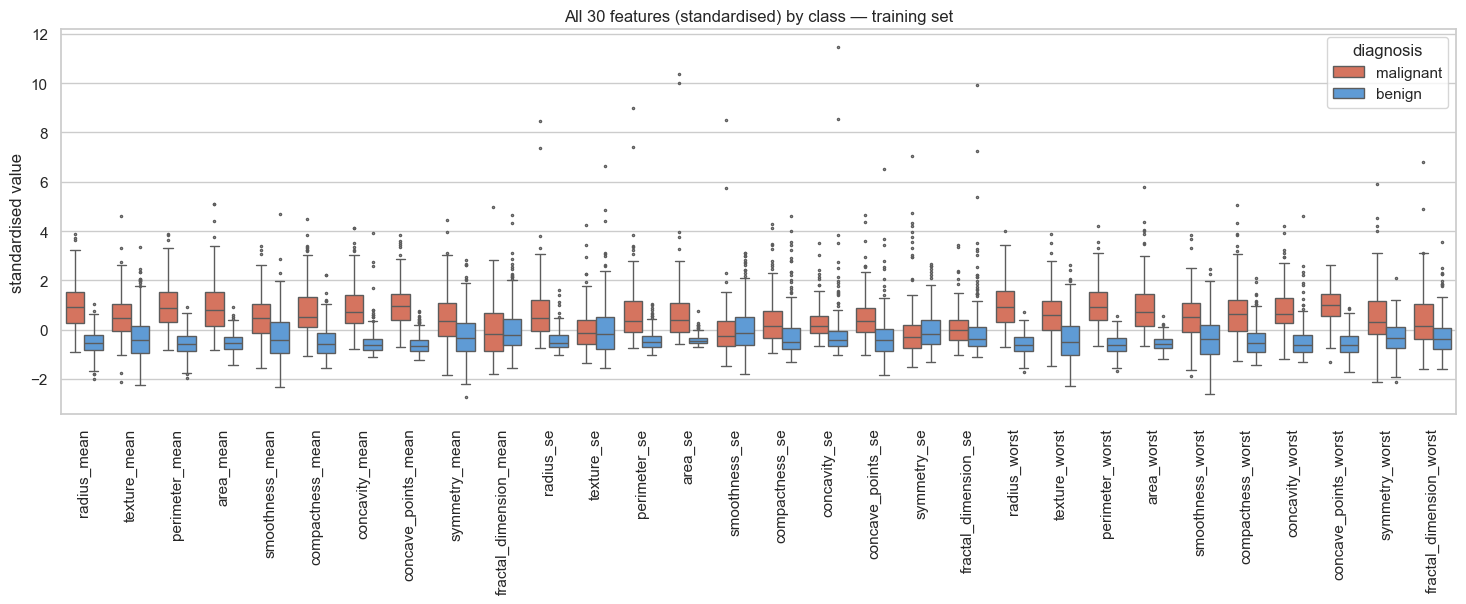

In [11]:
z = (X_train - X_train.mean()) / X_train.std()
long = z.assign(diagnosis=train["diagnosis"]).melt(id_vars="diagnosis", var_name="feature", value_name="z")
fig, ax = plt.subplots(figsize=(18, 5))
sns.boxplot(data=long, x="feature", y="z", hue="diagnosis", fliersize=1.5,
            palette={"benign": "#4C9BE8", "malignant": "#E8684C"}, ax=ax)
ax.tick_params(axis="x", rotation=90); ax.set_ylabel("standardised value"); ax.set_xlabel("")
ax.set_title("All 30 features (standardised) by class — training set")
savefig(fig, "01_boxplots"); plt.show()

**Observations.** Size-related features (radius, perimeter, area) and shape
irregularity (concavity, concave points, compactness) separate the classes strongly —
malignant nuclei are larger and more irregular. Texture separates moderately.
Smoothness, symmetry and fractal dimension (especially their `_se` versions) overlap
heavily and look weakly informative on their own. Many features (area, `_se`
features) are right-skewed with outliers, mostly on the malignant side.

### Univariate separability
Point-biserial correlation with the target and a univariate ROC-AUC for each feature
(computed on the training set).

In [12]:
uni = pd.DataFrame({
    "corr_with_malignant": X_train.corrwith(y_train),
    "univariate_auc": [max(roc_auc_score(y_train, X_train[f]), 1 - roc_auc_score(y_train, X_train[f]))
                       for f in FEATURE_NAMES],
}, index=FEATURE_NAMES).sort_values("univariate_auc", ascending=False)
uni.round(3)

,corr_with_malignant,univariate_auc
perimeter_worst,0.783,0.974
radius_worst,0.778,0.969
area_worst,0.732,0.968
concave_points_mean,0.776,0.964
concave_points_worst,0.786,0.963
perimeter_mean,0.740,0.946
area_mean,0.704,0.937
radius_mean,0.728,0.937
concavity_mean,0.684,0.933
area_se,0.534,0.921


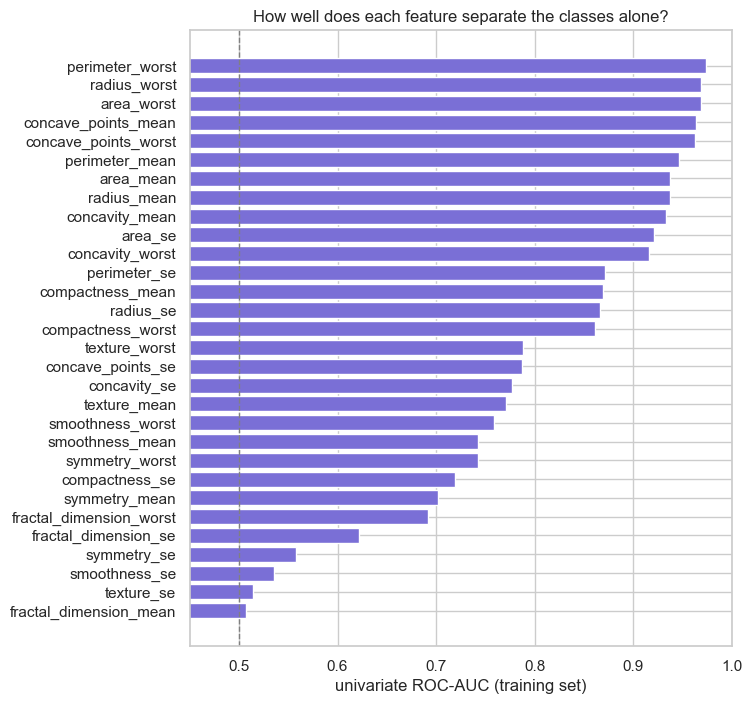

In [13]:
fig, ax = plt.subplots(figsize=(7, 8))
ax.barh(uni.index[::-1], uni["univariate_auc"][::-1], color="#7A6FD6")
ax.axvline(0.5, color="grey", ls="--", lw=1)
ax.set_xlim(0.45, 1); ax.set_xlabel("univariate ROC-AUC (training set)")
ax.set_title("How well does each feature separate the classes alone?")
savefig(fig, "01_univariate_auc"); plt.show()

### Pathological Grounding: Nuclear Pleomorphism (`_worst` vs `_mean`)
In clinical cytology, cancer diagnosis depends on *nuclear pleomorphism* (variation
in nuclear size and shape). In benign lesions, nuclei are uniform, so the worst
nucleus is barely larger than average. In malignant tumors, abnormal cells diverge
sharply from the mean.
Below, we quantify this divergence and plot `radius_worst` vs `radius_mean`.

In [14]:
pleomorph = pd.DataFrame({
    "mean_radius": train.groupby("diagnosis")["radius_mean"].mean(),
    "worst_radius": train.groupby("diagnosis")["radius_worst"].mean(),
    "absolute_divergence (worst - mean)": (train.groupby("diagnosis")["radius_worst"].mean() - 
                                           train.groupby("diagnosis")["radius_mean"].mean()),
    "relative_ratio (worst / mean)": (train["radius_worst"] / 
                                      train["radius_mean"]).groupby(train["diagnosis"]).mean()
}).round(3)
pleomorph

,mean_radius,worst_radius,absolute_divergence (worst - mean),relative_ratio (worst / mean)
diagnosis,,,,
benign,12.155,13.411,1.256,1.104
malignant,17.537,21.281,3.744,1.213


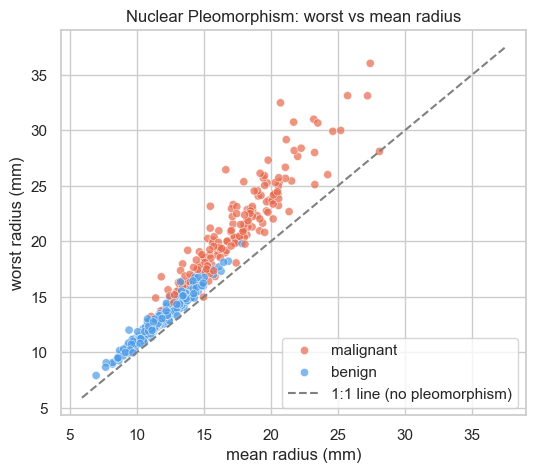

In [15]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.scatterplot(data=train, x="radius_mean", y="radius_worst", hue="diagnosis",
                palette={"benign": "#4C9BE8", "malignant": "#E8684C"}, alpha=0.7, s=35, ax=ax)
lims = [min(ax.get_xlim()[0], ax.get_ylim()[0]), max(ax.get_xlim()[1], ax.get_ylim()[1])]
ax.plot(lims, lims, ls="--", color="gray", lw=1.5, label="1:1 line (no pleomorphism)")
ax.set_title("Nuclear Pleomorphism: worst vs mean radius")
ax.set_xlabel("mean radius (mm)")
ax.set_ylabel("worst radius (mm)")
ax.legend()
savefig(fig, "01_nuclear_pleomorphism"); plt.show()

### Distributional Normality Diagnostics (Assessing Gaussian Assumptions)
Gaussian Naive Bayes (Member 2) and Linear Discriminant Analysis assume that
features follow normal distributions within each class.
We perform the Shapiro-Wilk test for normality on each feature separately for
benign and malignant training samples.

In [16]:
normality_rows = []
for f in FEATURE_NAMES:
    stat_b, p_b = shapiro(train[train["diagnosis"] == "benign"][f])
    stat_m, p_m = shapiro(train[train["diagnosis"] == "malignant"][f])
    normality_rows.append({
        "feature": f,
        "p_benign": p_b,
        "p_malignant": p_m,
        "normal_benign (p>0.05)": p_b > 0.05,
        "normal_malignant (p>0.05)": p_m > 0.05
    })
norm_df = pd.DataFrame(normality_rows).set_index("feature")
print(f"Features passing normality in benign: {norm_df['normal_benign (p>0.05)'].sum()} / 30")
print(f"Features passing normality in malignant: {norm_df['normal_malignant (p>0.05)'].sum()} / 30")
print("\nFeatures with most extreme non-normality in malignant class:")
norm_df[["p_benign", "p_malignant"]].sort_values("p_malignant").head(6)

Features passing normality in benign: 5 / 30
Features passing normality in malignant: 1 / 30

Features with most extreme non-normality in malignant class:


,p_benign,p_malignant
feature,,
area_se,6.697776e-13,1.042604e-18
smoothness_se,5.310623e-11,1.041587e-17
symmetry_se,2.119171e-10,4.848754e-16
perimeter_se,3.695117e-11,6.673308e-15
radius_se,1.115042e-12,8.680116e-14
concavity_se,1.540265e-27,9.109580e-11


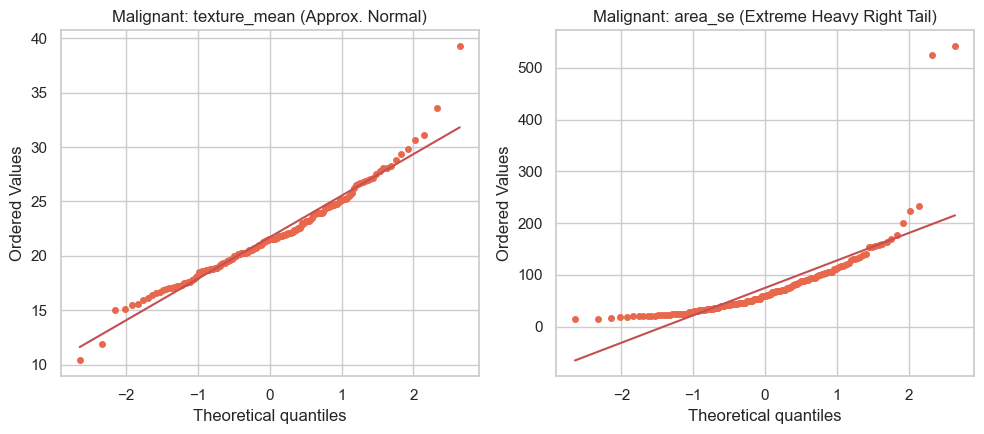

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
probplot(train[train["diagnosis"] == "malignant"]["texture_mean"], dist="norm", plot=axes[0])
axes[0].set_title("Malignant: texture_mean (Approx. Normal)")
axes[0].get_lines()[0].set_color("#E8684C")
axes[0].get_lines()[0].set_markersize(4)

probplot(train[train["diagnosis"] == "malignant"]["area_se"], dist="norm", plot=axes[1])
axes[1].set_title("Malignant: area_se (Extreme Heavy Right Tail)")
axes[1].get_lines()[0].set_color("#E8684C")
axes[1].get_lines()[0].set_markersize(4)
fig.tight_layout()
savefig(fig, "01_normality_qq"); plt.show()

**Finding on Normality:** Only 1 of 30 features passes normality in the malignant class!
Features such as `area_se` and `concavity_*` show extreme positive skewness and zero-inflation.
This mathematically explains why Gaussian Naive Bayes struggles on this dataset.

### The Clinical Ambiguity Zone (Single-Feature Overlap Analysis)
Even for the most discriminative individual feature (`radius_worst`, AUC 0.969),
there is a substantial overlap region where benign and malignant distributions meet.
Below, we define the "Ambiguity Zone" as $[\min(\text{malignant}), \max(\text{benign})]$
and count how many patients fall in this borderline gray area.

In [18]:
min_mal = train[train["diagnosis"] == "malignant"]["radius_worst"].min()
max_ben = train[train["diagnosis"] == "benign"]["radius_worst"].max()
overlap = train[(train["radius_worst"] >= min_mal) & (train["radius_worst"] <= max_ben)]
print(f"radius_worst ambiguity zone: [{min_mal:.2f}, {max_ben:.2f}] mm")
print(f"Samples in ambiguity zone: {len(overlap)} of {len(train)} ({len(overlap)/len(train):.1%})")
print(overlap["diagnosis"].value_counts())

radius_worst ambiguity zone: [12.84, 19.82] mm
Samples in ambiguity zone: 249 of 455 (54.7%)
diagnosis
benign       183
malignant     66
Name: count, dtype: int64


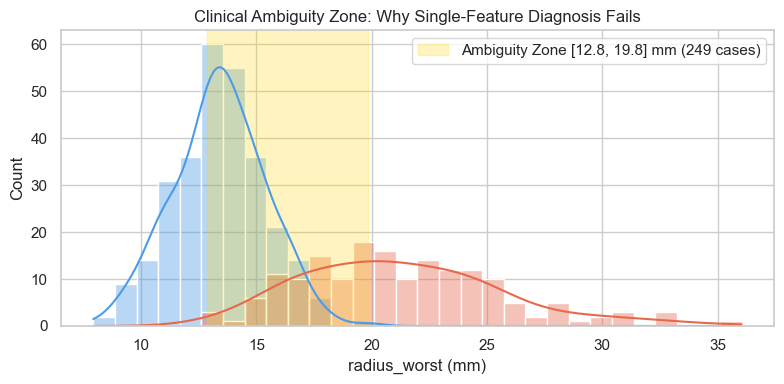

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=train, x="radius_worst", hue="diagnosis", kde=True,
             palette={"benign": "#4C9BE8", "malignant": "#E8684C"}, alpha=0.4, bins=30, ax=ax)
ax.axvspan(min_mal, max_ben, color="gold", alpha=0.25,
           label=f"Ambiguity Zone [{min_mal:.1f}, {max_ben:.1f}] mm ({len(overlap)} cases)")
ax.set_title("Clinical Ambiguity Zone: Why Single-Feature Diagnosis Fails")
ax.set_xlabel("radius_worst (mm)")
ax.legend()
fig.tight_layout()
savefig(fig, "01_ambiguity_zone"); plt.show()

Over 54 % of training cases fall within this overlapping range! A simple univariate
cutoff cannot safely triage these patients without unacceptable false alarms or missed
cancers. Multivariate models combining orthogonal dimensions are clinically required.

## 4. Correlations and Multicollinearity between features

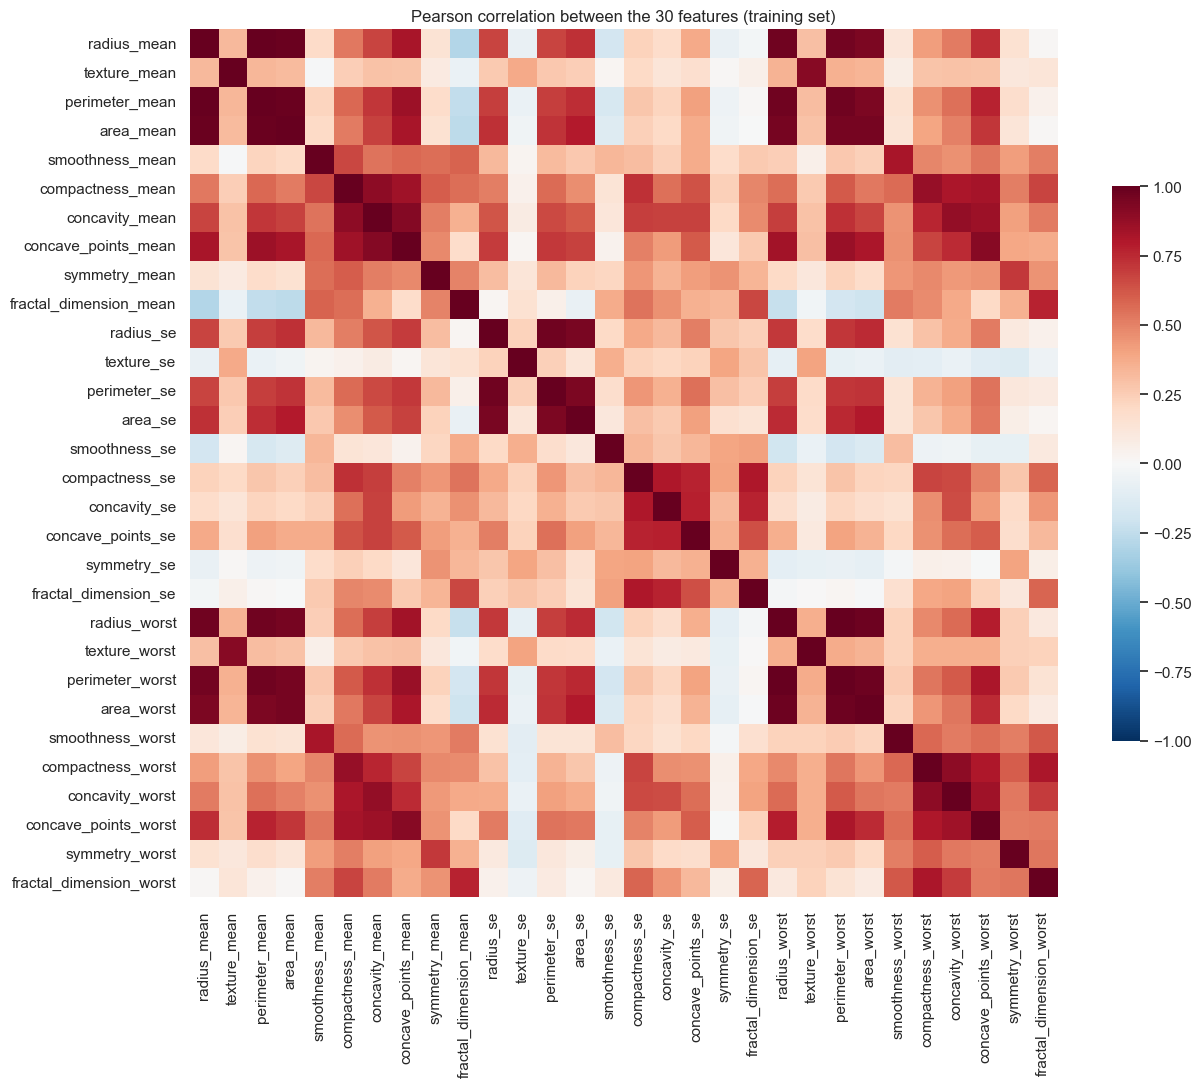

In [20]:
corr = X_train.corr()
fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True,
            cbar_kws={"shrink": .6}, ax=ax)
ax.set_title("Pearson correlation between the 30 features (training set)")
savefig(fig, "01_correlation_heatmap"); plt.show()

In [21]:
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().dropna().rename("r").reset_index().rename(columns={"level_0": "feature_1", "level_1": "feature_2"})
pairs["|r|"] = pairs["r"].abs()
high = pairs.sort_values("|r|", ascending=False)
print("pairs with |r| > 0.9:", int((high["|r|"] > 0.9).sum()), "of", len(high))
high.head(15).round(3)

pairs with |r| > 0.9: 21 of 435


,feature_1,feature_2,r,|r|
1,radius_mean,perimeter_mean,0.998,0.998
391,radius_worst,perimeter_worst,0.994,0.994
2,radius_mean,area_mean,0.987,0.987
57,perimeter_mean,area_mean,0.986,0.986
392,radius_worst,area_worst,0.983,0.983
407,perimeter_worst,area_worst,0.977,0.977
246,radius_se,perimeter_se,0.975,0.975
76,perimeter_mean,perimeter_worst,0.970,0.970
74,perimeter_mean,radius_worst,0.969,0.969
19,radius_mean,radius_worst,0.969,0.969


### Feature Phylogeny: Hierarchical Clustering Dendrogram
To reveal the functional groupings without relying on arbitrary column order, we perform
hierarchical agglomerative clustering using correlation distance ($1 - |r|$).

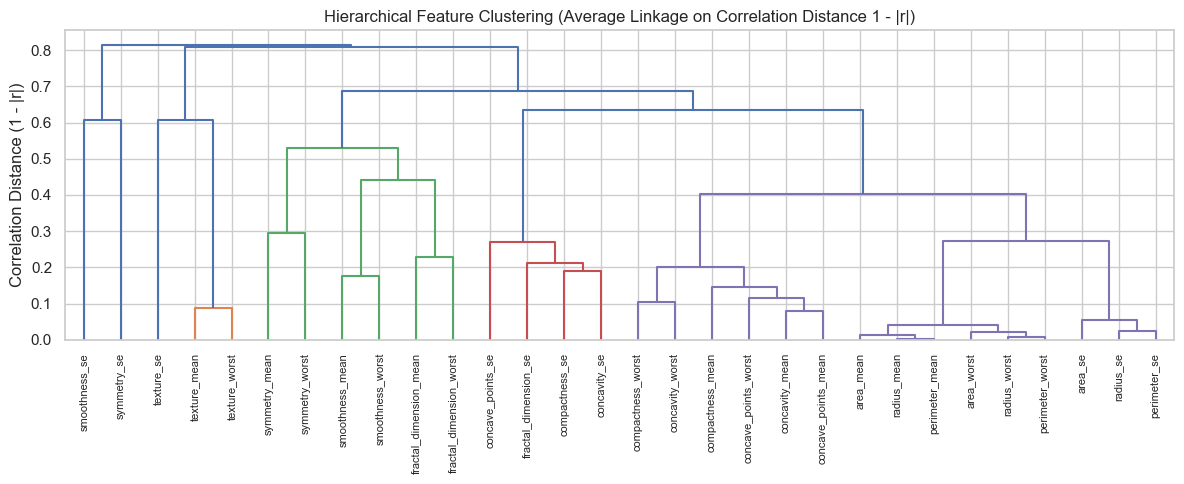

In [22]:
dist = 1 - corr.abs()
link = linkage(squareform(dist), method="average")
fig, ax = plt.subplots(figsize=(12, 5))
dendrogram(link, labels=FEATURE_NAMES, ax=ax, leaf_rotation=90, leaf_font_size=8)
ax.set_title("Hierarchical Feature Clustering (Average Linkage on Correlation Distance 1 - |r|)")
ax.set_ylabel("Correlation Distance (1 - |r|)")
fig.tight_layout()
savefig(fig, "01_feature_dendrogram"); plt.show()

The dendrogram clusters the 30 features into distinct functional branches:
1. **Size cluster**: `radius`, `perimeter`, `area` (mean, worst, and se).
2. **Irregularity cluster**: `concavity`, `concave_points`, `compactness`.
3. **Texture cluster**: `texture_mean` and `texture_worst`.
4. **SE / Noise cluster**: `smoothness_se`, `symmetry_se`, `fractal_dimension_se`.

This explains why feature selection (Member 6) succeeds when picking one feature
from each branch, and why univariate mutual information failed (it selected redundant
features from only the Size branch).

### Systemic Multicollinearity Diagnostic: Variance Inflation Factor (VIF)
While pairwise $|r| > 0.9$ identifies two-way correlations, multicollinearity often
involves linear combinations of multiple variables.
We compute the Variance Inflation Factor: $\text{VIF}_j = \frac{1}{1 - R_j^2}$,
where $R_j^2$ is the $R^2$ of regressing feature $j$ on all remaining 29 features.
A VIF $> 10$ indicates severe multicollinearity that destabilizes ordinary linear models.

In [23]:
vifs = {}
for col in X_train.columns:
    y_col = X_train[col]
    X_other = X_train.drop(columns=[col])
    r2 = LinearRegression().fit(X_other, y_col).score(X_other, y_col)
    vifs[col] = 1.0 / (1.0 - r2) if r2 < 1.0 else 1e5
vif_df = pd.Series(vifs).sort_values(ascending=False).to_frame(name="VIF")
print(f"Features with VIF > 10: {(vif_df['VIF'] > 10).sum()} of 30")
vif_df.head(12).round(1)

Features with VIF > 10: 24 of 30


,VIF
perimeter_mean,4110.6
radius_mean,4041.8
radius_worst,799.6
perimeter_worst,419.6
area_mean,348.2
area_worst,326.1
radius_se,80.9
perimeter_se,78.8
concavity_mean,74.9
concave_points_mean,70.7


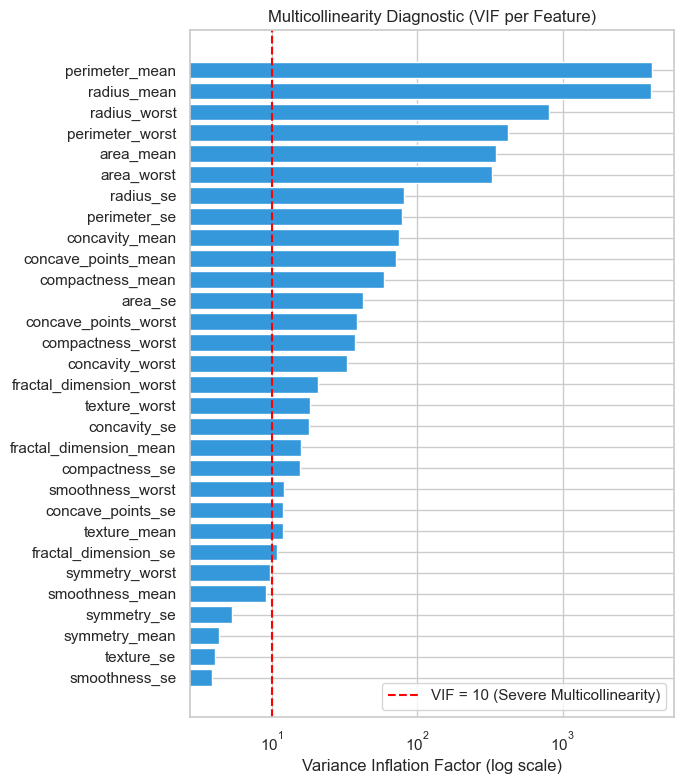

In [24]:
fig, ax = plt.subplots(figsize=(7, 8))
vif_sorted = vif_df["VIF"].sort_values(ascending=True)
ax.barh(vif_sorted.index, vif_sorted.values, color="#3498DB")
ax.axvline(10, color="red", ls="--", lw=1.5, label="VIF = 10 (Severe Multicollinearity)")
ax.set_xscale("log")
ax.set_xlabel("Variance Inflation Factor (log scale)")
ax.set_title("Multicollinearity Diagnostic (VIF per Feature)")
ax.legend()
fig.tight_layout()
savefig(fig, "01_vif_scores"); plt.show()

**VIF Finding:** Top size features have VIFs exceeding **4,000**!
This gives rigorous mathematical motivation for L1/L2 regularisation (Member 2)
and PCA orthogonalisation (Member 5).

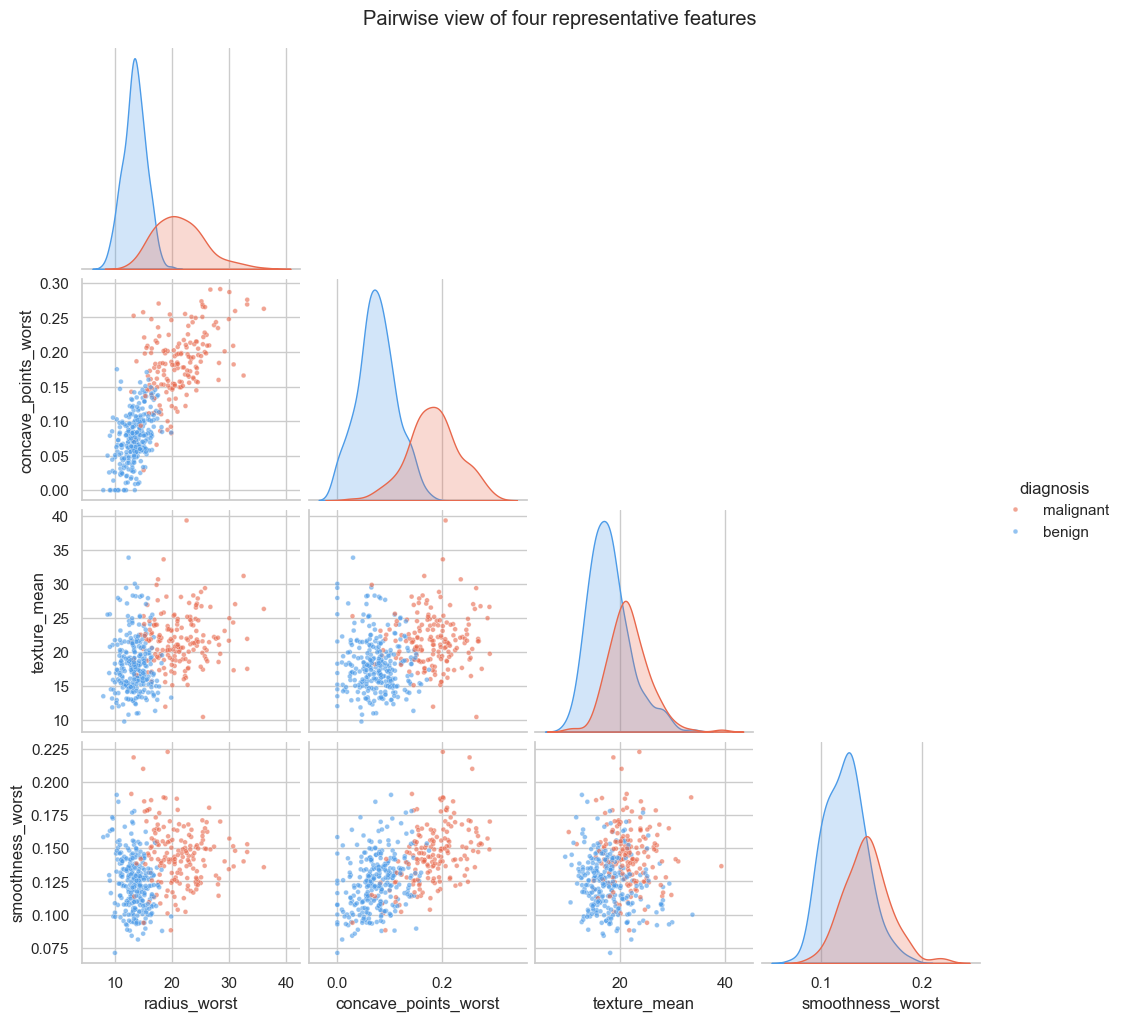

In [25]:
sel = ["radius_worst", "concave_points_worst", "texture_mean", "smoothness_worst"]
g = sns.pairplot(train[sel + ["diagnosis"]], hue="diagnosis", corner=True, plot_kws={"s": 12, "alpha": .6},
                 palette={"benign": "#4C9BE8", "malignant": "#E8684C"})
g.figure.suptitle("Pairwise view of four representative features", y=1.02)
savefig(g.figure, "01_pairplot"); plt.show()

## 5. Baseline models
Both are evaluated with the common 5-fold stratified CV on the training set.
LDA has no hyper-parameters worth tuning here (we use the default SVD solver), so it
serves as a strong, simple linear reference. LDA is reported only in this notebook
(it was listed in both Step 2 and Step 3 of the proposal).

In [26]:
rows = []
for key in ["dummy", "lda"]:
    pipe = build_pipeline(key)
    rows.append(cv_evaluate(pipe, X_train, y_train, name=display_name(key), key=key, feature_set="all 30"))
    save_best_params(key, {})
save_rows(rows, "cv_01_baselines.csv")
summarize(rows)

,model,key,feature_set,accuracy,precision,recall,specificity,f1,roc_auc
0,Majority baseline,dummy,all 30,0.6264 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,1.0000 ± 0.0000,0.0000 ± 0.0000,0.5000 ± 0.0000
1,LDA,lda,all 30,0.9560 ± 0.0231,0.9935 ± 0.0129,0.8882 ± 0.0600,0.9965 ± 0.0070,0.9369 ± 0.0342,0.9938 ± 0.0041


* The **majority baseline** always predicts *benign*: 62.6 % accuracy but **0 %
  malignant recall** — it misses every cancer. This is the clearest illustration of why
  accuracy alone is misleading here.
* **LDA** already reaches ≈95–96 % accuracy and ROC-AUC ≈ 0.99, so this is an
  "easy" dataset for linear models. Its weak point is malignant recall (≈ 0.89): it
  misses about 1 in 9 malignant tumours in CV. Every model below has to beat LDA to
  be interesting.

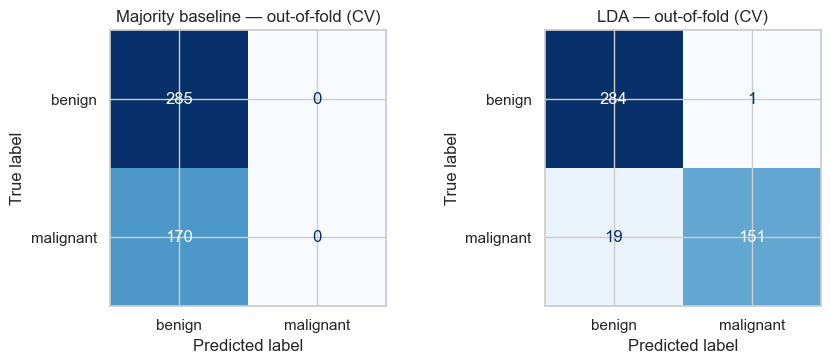

In [27]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, key in zip(axes, ["dummy", "lda"]):
    pred = cross_val_predict(build_pipeline(key), X_train, y_train, cv=get_cv())
    ConfusionMatrixDisplay.from_predictions(y_train, pred, display_labels=CLASS_NAMES, cmap="Blues",
                                            colorbar=False, ax=ax)
    ax.set_title(f"{display_name(key)} — out-of-fold (CV)")
fig.tight_layout(); savefig(fig, "01_baseline_confusion"); plt.show()

## Summary
* **Data Quality:** 569 samples, 30 numeric features, no missing values or duplicates; `id` dropped.
* **Class Imbalance:** Moderate imbalance (37 % malignant) → stratified splitting; recall/specificity/F1
  reported alongside accuracy.
* **Standardisation:** Features differ by 6 orders of magnitude → `StandardScaler` inside every pipeline.
* **Pathology (Pleomorphism):** Malignant tumors show marked divergence between `worst` and `mean` nuclei
  (average radius delta 3.74 mm vs 1.26 mm for benign).
* **Non-Normality:** 29 of 30 features violate normality in malignant cases, explaining why Gaussian Naive Bayes suffers.
* **Ambiguity Zone:** 54.7 % of training cases overlap in a single-feature boundary (`radius_worst`), demonstrating
  why univariate thresholding fails and multivariate ML is clinically necessary.
* **Severe Multicollinearity:** VIF values exceed 4,000 and 21 pairwise correlations exceed 0.90, providing mathematical
  proof that the 30 features collapse into far fewer dimensions (motivating PCA and Feature Selection).
* **Baseline Performance:** Majority baseline 62.6 % accuracy / 0 % recall; LDA sets reference at 95.6 % accuracy / 88.8 % recall.